Importamos los datos experimentales del funcionamiento de un motor de CD con diferentes señales de entrada

como se describe en:

https://doi.org/10.29057/icbi.v12iEspecial2.12165


In [ ]:
import pandas as pd


trainset = pd.read_csv("http://posgrado.itlp.edu.mx/datasets/fijo-escalones.csv",header=None)
validset = pd.read_csv("http://posgrado.itlp.edu.mx/datasets/fijo-tanh.csv",header=None)
testset = pd.read_csv("http://posgrado.itlp.edu.mx/datasets/fijo-rampas.csv",header=None)

X_train = trainset.values[:,1:4]
y_train = trainset.values[:,4]

X_valid = validset.values[:,1:4]
y_valid = validset.values[:,4]

X_test = testset.values[:,1:4]
y_test = testset.values[:,4]


Normalización de los datos usando Mínimos y Máximos

(un solo fit 3 transforms)

In [ ]:
from sklearn import preprocessing

scaler = preprocessing.MinMaxScaler()
scaler.fit(X_train)

Z_train = scaler.transform(X_train)
Z_valid = scaler.transform(X_valid)
Z_test = scaler.transform(X_test)


Definición y entrenamieno del MLP

In [ ]:
import keras

be=1000
for i in range(10):
  checkpoint_cb = keras.callbacks.ModelCheckpoint("motor.keras", save_best_only=True)
  early_stopping_cb = keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)
  model = keras.models.Sequential()
  model.add(keras.layers.Input([3]))
  model.add(keras.layers.Dense(50, activation= "leaky_relu"))
  model.add(keras.layers.Dense(10, activation= "leaky_relu"))
  model.add(keras.layers.Dense(1, activation= "linear"))
  model.compile(loss='mse',
              optimizer=keras.optimizers.RMSprop(0.001),
              metrics=['mae'])
  history = model.fit(Z_train, y_train, epochs=100,
                    validation_data=(Z_valid, y_valid),
                    callbacks=[checkpoint_cb, early_stopping_cb])
  e = model.evaluate(Z_valid, y_valid)
  if(e[0]<be):
    print(e)
    be = e[0]
    best_model = model


Epoch 1/100
442/442 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - loss: 2827.5767 - mae: 39.2441 - val_loss: 638.5871 - val_mae: 21.5288
Epoch 2/100
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 458.5773 - mae: 18.0737 - val_loss: 129.4888 - val_mae: 9.9627
Epoch 3/100
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 35.3620 - mae: 4.3918 - val_loss: 5.8069 - val_mae: 1.8276
Epoch 4/100
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 5.7232 - mae: 1.9321 - val_loss: 2.9566 - val_mae: 1.1329
Epoch 5/100
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 2.7703 - mae: 1.2987 - val_loss: 2.2652 - val_mae: 1.0694
Epoch 6/100
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 1.5677 - mae: 0.9620 - val_loss: 1.3135 - val_mae: 0.8698
Epoch 7/100
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.9070 - mae: 0.7337 - val_loss: 1.0754 - val_mae: 0.7615
Epoch 8/100
442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.6411 - mae: 0.6048 - val_loss: 0.8209 - val_mae: 0.6377
Epoch 9/100
442/442 ━━━━━━━━━━━━━━━

Evaluación del modelo entrenado

442/442 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


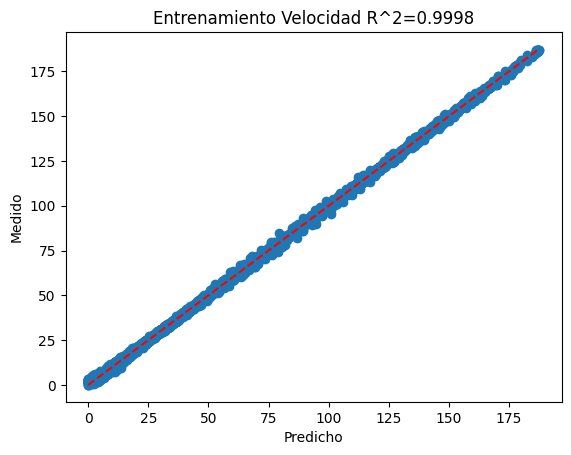

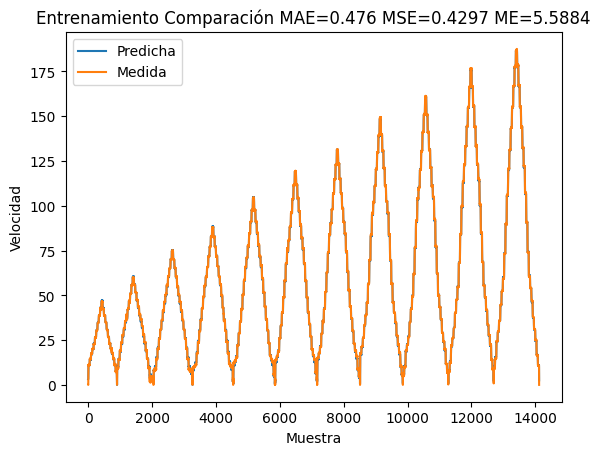

102/102 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


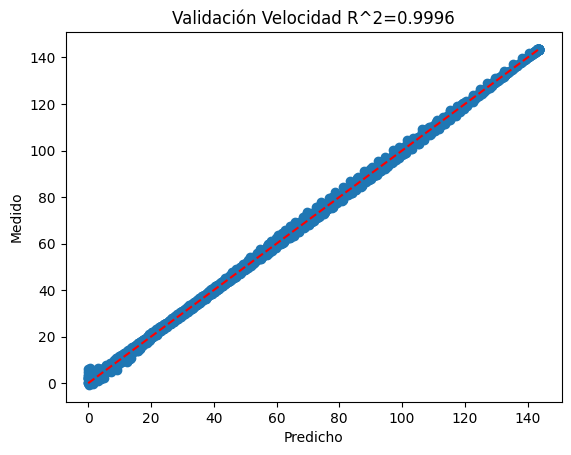

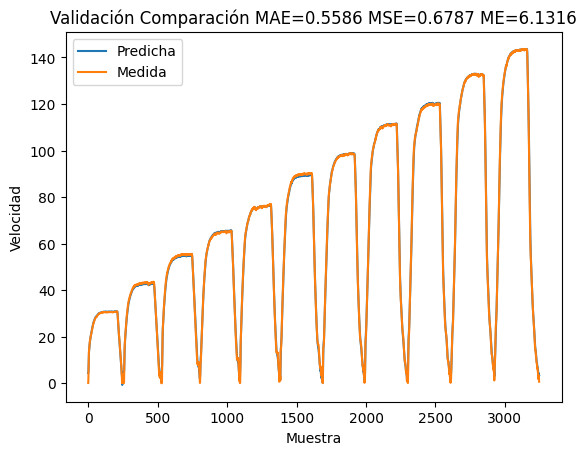

137/137 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


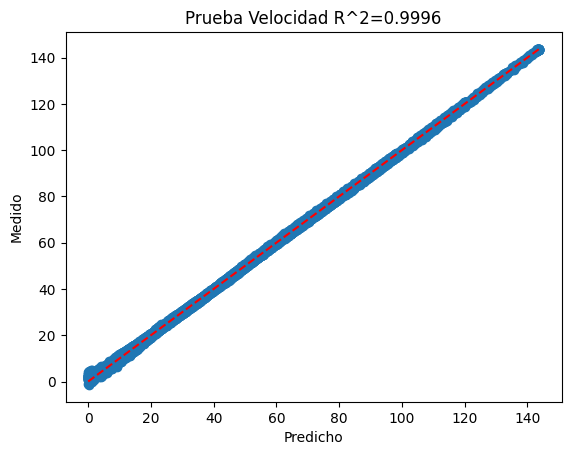

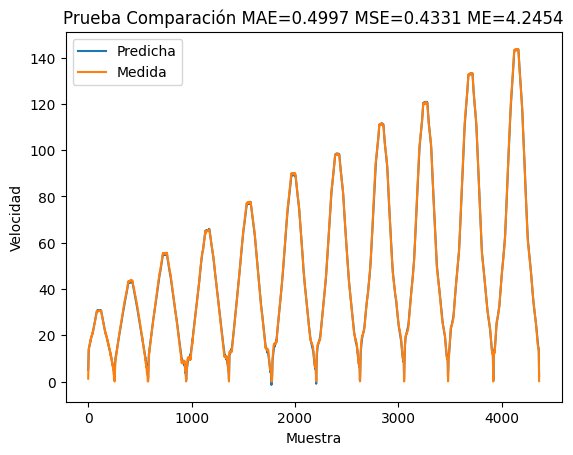

In [ ]:
import matplotlib.pyplot as plt
from sklearn import metrics

###############################################
def evalua(x,y,titulo):
  predicted = best_model.predict(x)
  r2=metrics.r2_score(y,predicted)
  plt.title(titulo+" Velocidad R^2="+str(round(r2,4)))
  plt.xlabel("Predicho")
  plt.ylabel("Medido")
  plt.scatter(y,predicted)
  lineStart = y.min()
  lineEnd = y.max()
  plt.plot([lineStart, lineEnd], [lineStart, lineEnd], color = 'r', linestyle='dashed')
  plt.show()

  mse=metrics.mean_squared_error(y,predicted)
  mae=metrics.mean_absolute_error(y,predicted)
  me=metrics.max_error(y,predicted)
  plt.title(titulo+" Comparación MAE="+str(round(mae,4))+" MSE="+str(round(mse,4)) + " ME=" +str(round(me,4)))
  plt.plot(predicted,label="Predicha")
  plt.plot(y,label="Medida")
  plt.xlabel("Muestra")
  plt.ylabel("Velocidad")
  plt.legend()
  plt.show()
###############################################
evalua(Z_train,y_train,"Entrenamiento")
evalua(Z_valid,y_valid,"Validación")
evalua(Z_test,y_test,"Prueba")